<a href="https://colab.research.google.com/github/Ch3ddarr/dsb_capstone/blob/main/capstone2/02_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **EDA for my second capstone**

In [13]:
import pandas as pd
import matplotlib as plt
import seaborn as sns

In [14]:
df = pd.read_csv("https://mcfp.felk.cvut.cz/publicDatasets/CTU-Malware-Capture-Botnet-42/detailed-bidirectional-flow-labels/capture20110810.binetflow")

In [15]:
# I wonder why am I not seeing the "non-null" values part of the info function?
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2824636 entries, 0 to 2824635
Data columns (total 15 columns):
 #   Column     Dtype  
---  ------     -----  
 0   StartTime  object 
 1   Dur        float64
 2   Proto      object 
 3   SrcAddr    object 
 4   Sport      object 
 5   Dir        object 
 6   DstAddr    object 
 7   Dport      object 
 8   State      object 
 9   sTos       float64
 10  dTos       float64
 11  TotPkts    int64  
 12  TotBytes   int64  
 13  SrcBytes   int64  
 14  Label      object 
dtypes: float64(3), int64(3), object(9)
memory usage: 323.3+ MB


In [16]:
df.shape

(2824636, 15)

In [17]:
# Now the question is, how do I split the botnet traffic from normal traffic
df.head()

,StartTime,Dur,Proto,SrcAddr,Sport,Dir,DstAddr,Dport,State,sTos,dTos,TotPkts,TotBytes,SrcBytes,Label
0,2011/08/10 09:46:53.047277,3550.182373,udp,212.50.71.179,39678,<->,147.32.84.229,13363,CON,0.0,0.0,12,875,413,flow=Background-UDP-Established
1,2011/08/10 09:46:53.048843,0.000883,udp,84.13.246.132,28431,<->,147.32.84.229,13363,CON,0.0,0.0,2,135,75,flow=Background-UDP-Established
2,2011/08/10 09:46:53.049895,0.000326,tcp,217.163.21.35,80,<?>,147.32.86.194,2063,FA_A,0.0,0.0,2,120,60,flow=Background
3,2011/08/10 09:46:53.053771,0.056966,tcp,83.3.77.74,32882,<?>,147.32.85.5,21857,FA_FA,0.0,0.0,3,180,120,flow=Background
4,2011/08/10 09:46:53.053937,3427.768066,udp,74.89.223.204,21278,<->,147.32.84.229,13363,CON,0.0,0.0,42,2856,1596,flow=Background-UDP-Established


In [18]:
# majority of botnet traffics run on IRC(Internet Relay Chat) and
# HTTP(Hypertext Transfer Protocol)
df.Proto.unique()

array(['udp', 'tcp', 'rtp', 'pim', 'icmp', 'arp', 'ipx/spx', 'rtcp',
       'igmp', 'ipv6-icmp', 'ipv6', 'udt', 'esp', 'unas', 'rarp'],
      dtype=object)

In [22]:
# Most of the traffic consists of UDP protocol. I hate this fact.
# There is too much of this traffic, almost everything consists of UDP
df.Proto.value_counts()

,count
Proto,
udp,2270083
tcp,507557
icmp,39694
rtp,2570
rtcp,2339
igmp,1803
arp,477
ipv6-icmp,58
ipx/spx,13


<Axes: title={'center': 'Almost all traffic is UDP traffic'}, xlabel='Proto'>

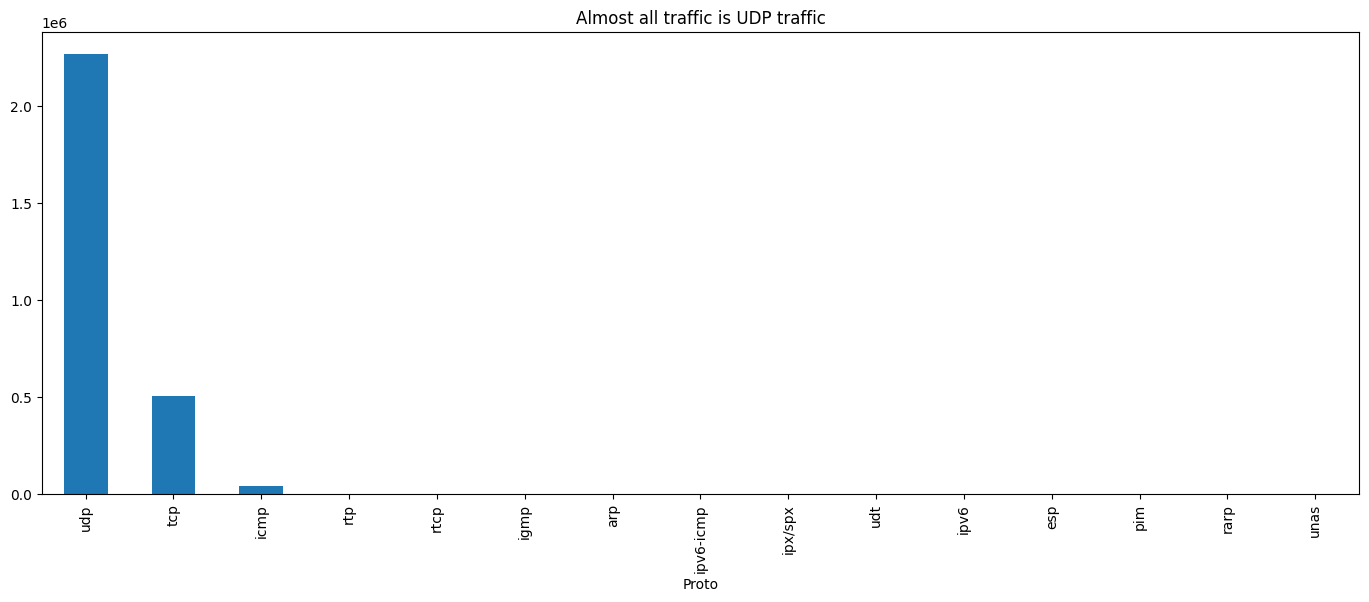

In [37]:
df.Proto.value_counts().plot(kind='bar', x='Proto', y='count', figsize=(17,6), title="Almost all traffic is UDP traffic")

In [19]:
# There is a lot of nulls, but I'll se how to handle those. I'm not sure for now
# if these nulls rig my data at all
df.isna().sum()

,0
StartTime,0
Dur,0
Proto,0
SrcAddr,0
Sport,9379
Dir,0
DstAddr,0
Dport,4390
State,1
sTos,10590


In [20]:
# I wonder what this "label" column is all about
df['Label'].unique()

array(['flow=Background-UDP-Established', 'flow=Background',
       'flow=Background-Established-cmpgw-CVUT',
       'flow=Background-TCP-Established',
       'flow=From-Background-CVUT-Proxy',
       'flow=To-Background-UDP-CVUT-DNS-Server',
       'flow=Background-UDP-Attempt',
       'flow=From-Normal-V42-UDP-CVUT-DNS-Server',
       'flow=Background-UDP-NTP-Established-1',
       'flow=To-Background-CVUT-WebServer',
       'flow=Background-google-analytics3',
       'flow=Background-Attempt-cmpgw-CVUT',
       'flow=To-Background-CVUT-Proxy',
       'flow=Background-google-analytics2',
       'flow=Background-google-analytics6', 'flow=From-Normal-V42-Jist',
       'flow=Background-google-webmail', 'flow=Background-TCP-Attempt',
       'flow=Background-google-analytics12',
       'flow=Background-google-analytics1',
       'flow=Background-google-analytics13',
       'flow=Background-google-analytics14', 'flow=To-Background-Jist',
       'flow=Background-ajax.google', 'flow=From-Nor

In [39]:
# I see there is a lot of labels here concerning different traffic, but also I
# see that there is a lot of botnet traffic labels which can be later useful
# to be honest, in my opinion
df.Label.value_counts()

# I wonder what does this "From-Botnet-V42-TCP-Established-HTTP-Ad-49" mean?
# I have to dig deeper

,count
Label,
flow=Background-UDP-Established,1169677
flow=To-Background-UDP-CVUT-DNS-Server,941706
flow=Background-TCP-Established,223543
flow=Background-Established-cmpgw-CVUT,137257
flow=Background-TCP-Attempt,105438
...,...
flow=From-Botnet-V42-TCP-Established-HTTP-Adobe-4,1
flow=From-Botnet-V42-TCP-Established-HTTP-Binary-Download-Custom-Port-5,1
flow=From-Botnet-V42-TCP-HTTP-Not-Encrypted-Down-2,1


In [41]:
# I wanted to check numerical values to see if there is anything that stands out
# For me, first things that stand out are 0s or ultimately big values
# Looking into this statistics, everything looks great to be honest.
df.describe()

,Dur,sTos,dTos,TotPkts,TotBytes,SrcBytes
count,2.824636e+06,2.814046e+06,2.629446e+06,2.824636e+06,2.824636e+06,2.824636e+06
mean,4.322060e+02,2.786664e-02,4.430591e-04,2.547990e+01,1.929134e+04,4.155290e+03
std,9.958423e+02,2.220372e+00,3.332693e-02,3.124788e+03,3.212186e+06,1.858530e+06
min,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00,6.000000e+01,0.000000e+00
25%,3.130000e-04,0.000000e+00,0.000000e+00,2.000000e+00,2.140000e+02,7.800000e+01
50%,1.194000e-03,0.000000e+00,0.000000e+00,2.000000e+00,2.610000e+02,8.300000e+01
75%,9.012607e+00,0.000000e+00,0.000000e+00,4.000000e+00,5.880000e+02,2.610000e+02
max,3.600031e+03,1.920000e+02,3.000000e+00,2.686731e+06,2.689640e+09,2.635366e+09


There is some domain knowledge needed to understand this. From the dataset source we have the following information:

- Infected hosts
    - 147.32.84.165: Windows XP (English version) Name: SARUMAN (Label: Botnet) (amount of bidirectional flows: 40961)
- Normal hosts:
    - 147.32.84.170 (amount of bidirectional flows: 18438, Label: Normal-V42-Stribrek)
    - 147.32.84.164 (amount of bidirectional flows: 7654, Label: Normal-V42-Grill)
    - 147.32.84.134 (amount of bidirectional flows: 3808, Label: Normal-V42-Jist)
    - 147.32.87.36 (amount of bidirectional flows: 269, Label: CVUT-WebServer. This normal host is not so reliable since is a webserver)
    - 147.32.80.9 (amount of bidirectional flows: 83, Label: CVUT-DNS-Server. This normal host is not so reliable since is a dns server)
    - 147.32.87.11 (amount of bidirectional flows: 6, Label: MatLab-Server. This normal host is not so reliable since is a matlab server)

In [47]:

df.SrcAddr.unique()

array(['212.50.71.179', '84.13.246.132', '217.163.21.35', ...,
       '83.46.238.157', '98.87.173.219', '88.222.4.220'],
      shape=(542093,), dtype=object)

In [52]:
# This column explains the direction of the traffic. I just don't understand
# whole nomenclature of this. Why is there somewhere a question mark, but I will
# figure this out
df.Dir.unique()

array(['  <->', '  <?>', '   ->', '   ?>', '  who', '  <-', '  <?'],
      dtype=object)

In [56]:
df.State.unique()

array(['CON', 'FA_A', 'FA_FA', 'PA_PA', 'FPA_FRPA', 'FPA_RPA',
       'FSPA_FSPA', 'PA_A', 'FA_RA', 'PA_FRA', 'FRPA_FPA', 'FPA_FA', 'A_',
       'INT', 'FA_', 'S_SA', 'RPA_RPA', 'FPA_FPA', 'PA_RPA', 'FSPA_FSRPA',
       'S_', 'SA_R', 'SRPA_SPA', 'SRA_SA', 'FPA_', 'RPA_PA', 'URP',
       'SRPA_FSRPA', 'FRPA_PA', 'URN', 'PA_', 'FA_FPA', 'SPA_FSPA',
       'PA_FRPA', 'PA_PAC', 'PA_FPA', 'FSRPA_FSPA', 'FRPA_RA', 'TXD',
       'RA_FA', 'FRA_', 'ECO', 'FRA_FPA', 'SRPA_FSPA', 'URH', 'SA_',
       'SRPA_SRA', 'FSA_FSA', 'RPA_FPA', 'FSRPA_SPA', 'S_RA', 'PA_R',
       'RA_A', 'RED', 'RA_', 'SPA_SRPA', 'FA_R', 'RA_FPA', 'A_PA', 'ECR',
       'FSPA_FSRA', 'SPA_SPA', 'FSRPA_FSRPA', 'SRA_FSA', 'FPA_PA',
       'SR_SA', 'FRPA_RPA', 'FPA_RA', 'FPA_FRA', 'FSPA_FSA', 'FRA_FA',
       'URFIL', '_FSPA', 'R_', 'FA_FRPA', 'SPA_FSRPA', 'FA_FRA',
       'RPA_FRPA', 'RPA_R', 'A_A', 'A_RA', 'SRPA_SA', 'SRA_RA',
       'FSPA_SPA', 'RPAC_PA', 'SPA_SRA', 'FSPAC_FSPA', 'PA_RA', 'FRPA_FA',
       'SR_A', 'A_R', 'SRP

In [62]:
# There is a lot of missing values, but through looking in each column I can
# conclude that I don't need to impute anything
df.isnull().sum()

,0
StartTime,0
Dur,0
Proto,0
SrcAddr,0
Sport,9379
Dir,0
DstAddr,0
Dport,4390
State,1
sTos,10590
